# Chapter 49: Liquidity, Fire Sales, and Financial Fragility

This notebook reruns four worked examples from the chapter: a fire sale that marks down collateral, a margin spiral, delegated monitoring with a run on the bank, and a credit crunch with and without a central bank facility. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def fire_sale_price(cash, supply, cap):
    """Cash-in-the-market price: min(cash / supply, use value). fire-sale-externality (EP-348).

    Book (ch049): 8,000 / 100 = 80; 8,000 / 169 = 47.34; with 12,000 the price is capped at the 100 use value.
    """
    return min(float(cash) / float(supply), float(cap))


def covenant_cure(debt, ratio, price, units):
    """Covenant debt <= ratio x price x units; machines x that cure a breach when proceeds repay debt.

    fire-sale-externality (EP-348). Solves debt - p x = ratio p (units - x). Book (ch049): debt 7,500,
    ratio 0.80, price 80, units 100: capacity 6,400, breach 1,100, x = 68.75, whole machines 69.
    """
    capacity = ratio * price * units
    breach = max(0.0, debt - capacity)
    x = breach / (price * (1 - ratio)) if breach > 0 else 0.0
    return {"capacity": capacity, "breach": breach, "x": x, "x_whole": math.ceil(x - 1e-9)}


def margin_capacity(equity, margin):
    """Largest position equity can finance at a margin: equity / margin.

    market-liquidity-and-funding-liquidity-spiral (EP-355). Book (ch049): 0.5 / 0.20 = 2.5; 0.5 / 0.10 = 5.
    """
    return float(equity) / float(margin)


def required_deleveraging(position, debt, margin):
    """Sale needed so the position fits equity / margin. EP-355.

    Book (ch049): position 9.5, debt 9, margin 0.20: equity 0.5, max 2.5, sale 7; margin 0.10: sale 4.5.
    """
    equity = position - debt
    max_position = margin_capacity(max(equity, 0.0), margin)
    return {"equity": equity, "max_position": max_position, "sale": max(0.0, position - max_position)}


def delegated_monitoring_cost(n_savers, n_loans, c_direct, c_specialist, G):
    """Direct versus delegated monitoring cost. financial-intermediation.

    Book (ch049): 100(20)(50) = 100,000; 20(400) + 2,000 = 10,000; saving 90,000; break-even G > 92,000.
    """
    direct = n_savers * n_loans * c_direct
    specialist = n_loans * c_specialist
    delegated = specialist + G
    return {"direct": direct, "specialist": specialist, "delegated": delegated, "saving": direct - delegated,
            "G_break_even": direct - specialist}


def liquidation_face(gap, price):
    """Face value that must be sold at a price per dollar of face to raise a cash gap.

    financial-intermediation and liquidity-crisis-credit-crunch. Book (ch049): 40,000 / 0.75 = 53,333.33;
    40 / 0.90 = 44.44. A gap of zero or less needs no sale.
    """
    return max(float(gap), 0.0) / float(price)


def capital_capacity(equity, ratio):
    """Lending a capital requirement allows: equity / ratio (zero when equity is not positive).

    liquidity-crisis-credit-crunch. Book (ch049): 5.56 / 0.10 = 55.6 (exact 5.5556 / 0.10 = 55.56).
    """
    return max(float(equity), 0.0) / float(ratio)


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(fire_sale_price=fire_sale_price, covenant_cure=covenant_cure, margin_capacity=margin_capacity, required_deleveraging=required_deleveraging, delegated_monitoring_cost=delegated_monitoring_cost, liquidation_face=liquidation_face, capital_capacity=capital_capacity)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'fire-sale-externality': {'cash': 8000,
                           'use_value': 100,
                           'supply_A': 100,
                           'units_B': 100,
                           'debt_B': 7500,
                           'ratio': 0.8,
                           'p_first': 80,
                           'capacity_first': 6400,
                           'breach': 1100,
                           'naive_units': 13.75,
                           'x': 68.75,
                           'x_whole': 69,
                           'supply_total': 169,
                           'p_clear': 47.34,
                           'p_clear_4dp': 47.3373,
                           'proceeds': 3266.27,
                           'debt_after': 4233.73,
                           'capacity_after': 1173.96,
                           'shortfall': 3059.76,
                           'cash_comparison': 12000},
 'market-liquidity-and-funding-liquidity-spiral': {'position': 10,
                                                   'debt': 9,
                                                   'margin': 0.1,
                                                   'required_equity': 1,
                                                   'mark': 9.5,
                                                   'equity': 0.5,
                                                   'new_margin': 0.2,
                                                   'max_position': 2.5,
                                                   'sale': 7,
                                                   'max_position_old': 5,
                                                   'sale_old': 4.5,
                                                   'extra_sale': 2.5},
 'financial-intermediation': {'savers': 100,
                              'deposit': 1000,
                              'loans': 20,
                              'loan_size': 5000,
                              'c_direct': 50,
                              'c_specialist': 400,
                              'G': 2000,
                              'direct': 100000,
                              'delegated': 10000,
                              'saving': 90000,
                              'G_break_even': 92000,
                              'reserves': 20000,
                              'withdraw_small': 15000,
                              'withdraw': 60000,
                              'gap': 40000,
                              'price': 0.75,
                              'face': 53333.33},
 'liquidity-crisis-credit-crunch': {'cash': 20,
                                    'loans': 100,
                                    'claims': 110,
                                    'equity_before': 10,
                                    'due': 60,
                                    'gap': 40,
                                    'price': 0.9,
                                    'face': 44.44,
                                    'loss': 4.44,
                                    'loans_left': 55.56,
                                    'claims_left': 50,
                                    'equity': 5.56,
                                    'ratio': 0.1,
                                    'capacity_printed_as': 55.6,
                                    'capacity_exact_2dp': 55.56,
                                    'facility_equity': 10},
 'constructed': {'fire-sale-externality': {'cash': [9000, 10000],
                                           'p_9000': 76.92,
                                           'shortfall_9000': 1084.62},
                 'market-liquidity-and-funding-liquidity-spiral': {'margin': [0.15, 0.25],
                                                                   'mark': [9.7, 9.8],
                                                                   'sale_9_8_015': 4.47},
                 'financial-intermediation': {'withdraw': 40000,
                                              'price': [0.85, 0.95],
                                              'face_40000_085': 23529.41},
                 'liquidity-crisis-credit-crunch': {'price': [0.8, 1.0], 'equity_080': 0}}}


def fire_sale_state(cash):
    """Fund B's position for a given pool of specialist cash (A sells 100 machines, B owns 100, owes 7,500)."""
    p1 = finance.fire_sale_price(cash, 100, 100)
    cov = finance.covenant_cure(7500, 0.80, p1, 100)
    out = {"p1": p1, "capacity": cov["capacity"], "breach": cov["breach"], "x": cov["x"], "x_whole": cov["x_whole"]}
    if cov["breach"] > 0:
        x = cov["x_whole"]
        p2 = finance.fire_sale_price(cash, 100 + x, 100)
        proceeds = x * p2
        debt2 = 7500 - proceeds
        cap2 = 0.80 * (100 - x) * p2
        out.update(p2=p2, proceeds=proceeds, debt2=debt2, cap2=cap2, shortfall=max(0.0, debt2 - cap2))
    else:
        out.update(p2=p1, proceeds=0.0, debt2=7500.0, cap2=cov["capacity"], shortfall=0.0)
    return out


def fire_sale_picture(cash=8000):
    s = fire_sale_state(cash)
    fig, (ax1, ax2) = new_figure(ncols=2)
    breach = s["breach"] > 0
    xs = np.arange(2)
    prices = [s["p1"], s["p2"]]
    ax1.bar(xs, prices, color=[PALETTE["teal"], PALETTE["terracotta"] if breach else PALETTE["teal"]], width=0.55)
    ax1.set_xticks(xs, ["A sells alone", "A and B sell" if breach else "B need not sell"])
    for x, v in zip(xs, prices):
        label(ax1, x, v, money(v), dx=0, dy=3, ha="center")
    ax1.axhline(100, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4, label=r"use value \$100")
    ax1.legend(loc="upper right", frameon=False)
    ax1.set_ylim(0, 140)
    ax1.set_ylabel("Price per machine (dollars)")
    ax1.set_xlabel("Sellers reaching the specialists")
    names = ["Before B sells", "After B sells"] if breach else ["First mark", "No sale by B"]
    debts = [7500, s["debt2"]]
    caps = [s["capacity"], s["cap2"]]
    w = 0.36
    ax2.bar(xs - w / 2, debts, width=w, color=PALETTE["navy"], label="B's debt")
    ax2.bar(xs + w / 2, caps, width=w, color=PALETTE["gold"], label="80% of marked collateral")
    for x, d, c in zip(xs, debts, caps):
        label(ax2, x - w / 2, d, num(d, 0), dx=0, dy=3, ha="center")
        label(ax2, x + w / 2, c, num(c, 0), dx=0, dy=3, ha="center")
    ax2.set_xticks(xs, names)
    ax2.set_ylim(0, 10500)
    ax2.legend(loc="upper right", frameon=False)
    ax2.set_ylabel("Dollars")
    ax2.set_xlabel("Fund B")
    metrics = {"First mark": money(s["p1"]), "Covenant capacity at first mark": money(s["capacity"]),
               "Breach": money(s["breach"])}
    if breach:
        metrics.update({"Machines B plans to sell": f"{num(s['x'])}, so {s['x_whole']}",
                        "Clearing price with both sellers": money(s["p2"]),
                        "Remaining shortfall": money(s["shortfall"])})
        interp = (f"With {money(cash, 0)} of specialist cash, A alone clears at {num(cash, 0)} / 100 = {num(s['p1'])}. "
                  f"B's capacity is 0.80 x {num(s['p1'])} x 100 = {num(s['capacity'])}, a breach of 7,500 - "
                  f"{num(s['capacity'])} = {num(s['breach'])}. Solving 7,500 - {num(s['p1'])}x = 0.80 x {num(s['p1'])} "
                  f"x (100 - x) gives x = {num(s['x'])}, so B plans {s['x_whole']} sales. With {100 + s['x_whole']} "
                  f"machines for sale the price falls to {num(cash, 0)} / {100 + s['x_whole']} = {num(s['p2'], 4)}. "
                  f"Debt becomes {num(s['debt2'])} against capacity {num(s['cap2'])}, so a shortfall of "
                  f"{num(s['shortfall'])} remains: the cure does not work once B's own sale moves the price.")
        steps = [f"First mark = {num(cash, 0)} / 100 = {num(s['p1'])}",
                 f"Capacity = 0.80 x {num(s['p1'])} x 100 = {num(s['capacity'])}",
                 f"Breach = 7,500 - {num(s['capacity'])} = {num(s['breach'])}",
                 f"x = {num(s['breach'])} / ({num(s['p1'])} x 0.20) = {num(s['x'])}, round up to {s['x_whole']}",
                 f"Clearing price = {num(cash, 0)} / {100 + s['x_whole']} = {num(s['p2'], 4)}",
                 f"Debt = 7,500 - {s['x_whole']} x {num(s['p2'], 4)} = 7,500 - {num(s['proceeds'])} = {num(s['debt2'])}",
                 f"Capacity = 0.80 x {100 - s['x_whole']} x {num(s['p2'], 4)} = {num(s['cap2'])}",
                 f"Shortfall = {num(s['debt2'])} - {num(s['cap2'])} = {num(s['shortfall'])}"]
    else:
        metrics.update({"Machines B plans to sell": "0", "Clearing price with both sellers": money(s["p2"]),
                        "Remaining shortfall": money(0)})
        interp = (f"With {money(cash, 0)} of specialist cash, A's 100 machines sell at min({num(cash, 0)} / 100, 100) = "
                  f"{num(s['p1'])}, the full use value. B's capacity is 0.80 x {num(s['p1'])} x 100 = {num(s['capacity'])}, "
                  f"above its 7,500 debt, so there is no breach and no second sale.")
        steps = [f"Price = min({num(cash, 0)} / 100, 100) = {num(s['p1'])}",
                 f"Capacity = 0.80 x {num(s['p1'])} x 100 = {num(s['capacity'])}",
                 f"Cushion = {num(s['capacity'])} - 7,500 = {num(s['capacity'] - 7500)}, no sale needed"]
    alt = (f"Left: price per machine {num(s['p1'])} when A sells alone and {num(s['p2'])} when B also sells. Right: "
           f"B's debt against 80 percent of marked collateral before and after; remaining shortfall {num(s['shortfall'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def spiral_picture(margin=0.20, mark=9.5):
    r = finance.required_deleveraging(mark, 9, margin)
    base = finance.required_deleveraging(mark, 9, 0.10)
    extra = r["sale"] - base["sale"]
    fig, ax = new_figure()
    names = ["Marked position", "Financeable", "Required sale"]
    vals = [mark, r["max_position"], r["sale"]]
    xs = np.arange(3)
    ax.bar(xs, vals, color=[PALETTE["navy"], PALETTE["teal"], PALETTE["terracotta"]], width=0.55)
    for x, v in zip(xs, vals):
        label(ax, x, v, num(v), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 12)
    ax.set_ylabel("Million dollars")
    ax.set_xlabel(f"Margin {num(margin * 100, 0)} percent, debt 9")
    metrics = {"Equity": num(r["equity"]), "Largest financeable position": num(r["max_position"]),
               "Required sale": num(r["sale"]), "Sale at a 10 percent margin": num(base["sale"]),
               "Extra sale from the margin change": num(extra)}
    e = num(r["equity"])
    interp = (f"Equity is {num(mark, 1)} - 9 = {e} million. At a {num(margin * 100, 0)} percent margin it finances "
              f"{e} / {num(margin)} = {num(r['max_position'])} million, so the dealer sells {num(mark, 1)} - "
              f"{num(r['max_position'])} = {num(r['sale'])} million. At 10 percent the sale would be {num(mark, 1)} - "
              f"{e} / 0.10 = {num(base['sale'])}, so the margin change "
              + (f"adds {num(extra)} million of selling." if extra > 1e-9 else "adds nothing: this is the old margin."))
    steps = [f"Equity = {num(mark, 1)} - 9 = {e}", f"Financeable = {e} / {num(margin)} = {num(r['max_position'])}",
             f"Sale = {num(mark, 1)} - {num(r['max_position'])} = {num(r['sale'])}",
             f"Sale at 10 percent = {num(mark, 1)} - {e} / 0.10 = {num(base['sale'])}",
             f"Extra = {num(r['sale'])} - {num(base['sale'])} = {num(extra)}"]
    alt = (f"Bars: marked position {num(mark, 1)}, financeable position {num(r['max_position'])} and required sale "
           f"{num(r['sale'])} million dollars at a {num(margin * 100, 0)} percent margin.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def intermediation_picture(withdraw=60000, price=0.75):
    mon = finance.delegated_monitoring_cost(100, 20, 50, 400, 2000)
    gap = max(0.0, withdraw - 20000)
    face = finance.liquidation_face(gap, price)
    loss = face - gap
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.bar([0, 1], [mon["direct"], mon["delegated"]], color=[PALETTE["grey"], PALETTE["teal"]], width=0.55)
    for x, v in zip([0, 1], [mon["direct"], mon["delegated"]]):
        label(ax1, x, v, num(v, 0), dx=0, dy=3, ha="center")
    ax1.set_xticks([0, 1], ["Direct", "Delegated"])
    ax1.set_ylim(0, 120000)
    ax1.set_ylabel("Monitoring cost (dollars)")
    ax1.set_xlabel("Who reviews the 20 borrowers")
    ax2.bar([0], [20000], color=PALETTE["gold"], width=0.55, label="reserves")
    ax2.bar([1], [80000 - face], color=PALETTE["navy"], width=0.55, label="loans kept")
    if face > 0:
        ax2.bar([1], [face], bottom=[80000 - face], color=PALETTE["terracotta"], width=0.55, label="loan face sold")
    label(ax2, 0, 20000, num(20000, 0), dx=0, dy=3, ha="center")
    label(ax2, 1, 80000, f"sold {num(face)}" if face > 0 else "nothing sold", dx=0, dy=3, ha="center")
    ax2.set_xticks([0, 1], ["Reserves", "Loans"])
    ax2.set_ylim(0, 100000)
    ax2.legend(loc="upper left", frameon=False)
    ax2.set_ylabel("Dollars")
    ax2.set_xlabel(f"Withdrawals {num(withdraw, 0)}, price {num(price)}")
    metrics = {"Direct monitoring cost": money(mon["direct"], 0), "Delegated cost": money(mon["delegated"], 0),
               "Saving": money(mon["saving"], 0), "Cash gap": money(gap), "Loan face sold": money(face),
               "Loss from the sale": money(loss)}
    head = (f"Direct review costs 100 x 20 x 50 = 100,000 and delegation 20 x 400 + 2,000 = 10,000, a saving of "
            f"90,000. ")
    if gap > 0:
        interp = head + (f"Withdrawals of {num(withdraw, 0)} exceed the 20,000 of reserves by {num(gap, 0)}, so the bank "
                         f"sells {num(gap, 0)} / {num(price)} = {num(face)} of loan face, losing {num(face)} - "
                         f"{num(gap, 0)} = {num(loss)}.")
        steps = ["Direct = 100 x 20 x 50 = 100,000", "Delegated = 20 x 400 + 2,000 = 10,000",
                 f"Gap = {num(withdraw, 0)} - 20,000 = {num(gap, 0)}",
                 f"Face sold = {num(gap, 0)} / {num(price)} = {num(face)}",
                 f"Loss = {num(face)} - {num(gap, 0)} = {num(loss)}"]
    else:
        interp = head + (f"Withdrawals of {num(withdraw, 0)} are paid from the 20,000 of reserves, so no loans are sold "
                         f"and the sale price does not matter.")
        steps = ["Direct = 100 x 20 x 50 = 100,000", "Delegated = 20 x 400 + 2,000 = 10,000",
                 f"Gap = {num(withdraw, 0)} - 20,000 is negative, so no sale"]
    alt = (f"Left: monitoring cost 100,000 direct versus 10,000 delegated. Right: 20,000 of reserves and 80,000 of "
           f"loans, of which {num(face)} of face is sold at price {num(price)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def crunch_state(price, facility):
    if facility == "on":
        return {"face": 0.0, "loss": 0.0, "loans": 100.0, "equity": 100 - 50 - 40.0,
                "capacity": finance.capital_capacity(10, 0.10)}
    face = finance.liquidation_face(40, price)
    loans = 100 - face
    equity = loans - 50
    return {"face": face, "loss": face - 40, "loans": loans, "equity": equity,
            "capacity": finance.capital_capacity(equity, 0.10)}


def crunch_picture(price=0.90, facility="off"):
    s = crunch_state(price, facility)
    fig, ax = new_figure()
    xs = np.arange(2)
    w = 0.36
    eq = [10, s["equity"]]
    cap = [100, s["capacity"]]
    ax.bar(xs - w / 2, eq, width=w, color=PALETTE["navy"], label="equity")
    ax.bar(xs + w / 2, cap, width=w, color=PALETTE["teal"], label="lending capacity")
    for x, e, c in zip(xs, eq, cap):
        label(ax, x - w / 2, e, num(e), dx=0, dy=3, ha="center")
        label(ax, x + w / 2, c, num(c), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, ["Before the payment", "After the payment"])
    ax.set_ylim(0, 125)
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Million dollars")
    ax.set_xlabel("Central bank facility " + facility)
    metrics = {"Funding gap": num(40), "Loan face sold": num(s["face"]), "Liquidation loss": num(s["loss"]),
               "Equity after": num(s["equity"]), "Lending capacity": num(s["capacity"])}
    if facility == "on":
        interp = ("The facility advances the 40 million gap, so no loans are sold. The bank keeps 100 of loans and owes "
                  "50 to private claimants plus 40 to the facility: equity is 100 - 50 - 40 = 10.00 million, supporting "
                  "10 / 0.10 = 100.00 million of lending. The sale price does not matter while the facility is on.")
        steps = ["Face sold = 0", "Equity = 100 - 50 - 40 = 10.00", "Capacity = 10.00 / 0.10 = 100.00"]
    else:
        e = s["equity"]
        ed = 2 if abs(100 * e - round(100 * e)) < 1e-9 else 4
        tail = (f"supports {num(e, ed)} / 0.10 = {num(s['capacity'])} million of lending." if e > 1e-9 else
                "is wiped out, and the bank can support no new lending without fresh capital.")
        interp = (f"Cash covers 20 of the 60 due, leaving a gap of 40. At {num(price)} per dollar the bank sells "
                  f"40 / {num(price)} = {num(s['face'])} of loans, a loss of {num(s['face'])} - 40 = {num(s['loss'])}. "
                  f"Loans left are 100 - {num(s['face'])} = {num(s['loans'])}, so equity of {num(s['loans'])} - 50 = "
                  f"{num(e)} " + tail)
        if abs(price - 0.90) < 1e-9:
            interp += " The book rounds equity to 5.56 first and prints 55.6."
        steps = [f"Face sold = 40 / {num(price)} = {num(s['face'])}", f"Loss = {num(s['face'])} - 40 = {num(s['loss'])}",
                 f"Loans left = 100 - {num(s['face'])} = {num(s['loans'])}",
                 f"Equity = {num(s['loans'])} - 50 = {num(e)}", f"Capacity = {num(e, ed)} / 0.10 = {num(s['capacity'])}"]
    alt = (f"Equity and lending capacity before (10 and 100) and after the 60 million payment ({num(s['equity'])} and "
           f"{num(s['capacity'])}), facility {facility}, sale price {num(price)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Fire-sale externality: a fire sale marks down everyone's collateral

Specialists hold \$8,000; A sells 100 machines; B owns 100, owes \$7,500, covenant 80 percent:

$$p=\frac{8{,}000}{100}=80,\qquad 0.80(80)(100)=6{,}400$$

$$7{,}500-80x=0.80(80)(100-x)$$

$$p=\frac{8{,}000}{169}\approx47.34,\qquad 0.80(31)(47.3373)\approx1{,}173.96$$

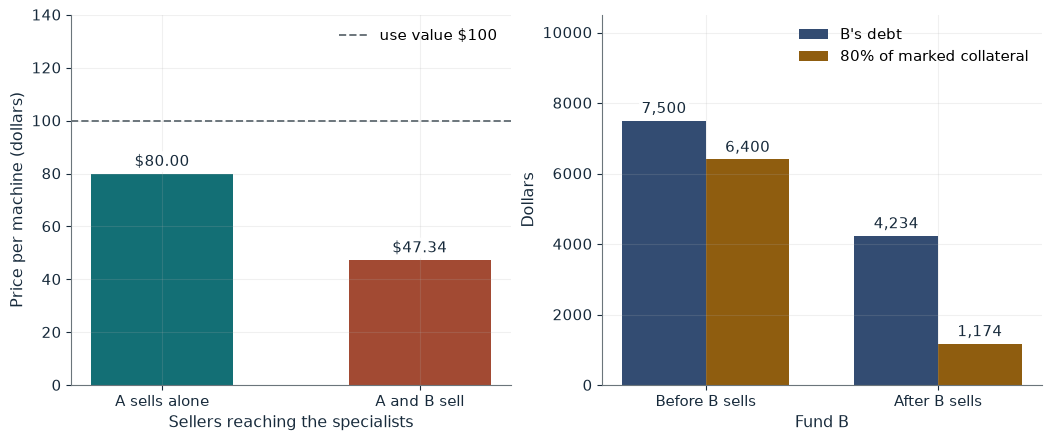

First mark                        $80.00
Covenant capacity at first mark   $6,400.00
Breach                            $1,100.00
Machines B plans to sell          68.75, so 69
Clearing price with both sellers  $47.34
Remaining shortfall               $3,059.76

Worked steps:
  1. First mark = 8,000 / 100 = 80.00
  2. Capacity = 0.80 x 80.00 x 100 = 6,400.00
  3. Breach = 7,500 - 6,400.00 = 1,100.00
  4. x = 1,100.00 / (80.00 x 0.20) = 68.75, round up to 69
  5. Clearing price = 8,000 / 169 = 47.3373
  6. Debt = 7,500 - 69 x 47.3373 = 7,500 - 3,266.27 = 4,233.73
  7. Capacity = 0.80 x 31 x 47.3373 = 1,173.96
  8. Shortfall = 4,233.73 - 1,173.96 = 3,059.76

With $8,000 of specialist cash, A alone clears at 8,000 / 100 = 80.00. B's capacity is 0.80 x 80.00 x 100 = 6,400.00, a breach of 7,500 - 6,400.00 = 1,100.00. Solving 7,500 - 80.00x = 0.80 x 80.00 x (100 - x) gives x = 68.75, so B plans 69 sales. With 169 machines for sale the price falls to 8,000 / 169 = 47.3373. Debt becomes 4,233.7

In [2]:
show(fire_sale_picture(cash=8000))

Change one input, `cash`, and hold the others at the book's values:

In [3]:
sweep(fire_sale_picture, 'cash', [8000, 9000, 10000, 12000], {}, ['First mark', 'Breach', 'Clearing price with both sellers', 'Remaining shortfall'])

cash | First mark | Breach | Clearing price with both sellers | Remaining shortfall
8000 | $80.00 | $1,100.00 | $47.34 | $3,059.76
9000 | $90.00 | $300.00 | $76.92 | $1,084.62
10000 | $100.00 | $0.00 | $100.00 | $0.00
12000 | $100.00 | $0.00 | $100.00 | $0.00


B plans to sell 69 machines, but with both funds selling the price falls to 47.34 and a shortfall of \$3,059.76 remains. With \$10,000 or more of specialist cash the price stays at the \$100 use value and no breach occurs.

## 2. Liquidity spiral: margin increases force extra selling

Debt 9, mark 9.5 (million dollars):

$$\frac{0.5}{0.20}=2.5,\qquad 9.5-2.5=7,\qquad 9.5-\frac{0.5}{0.10}=4.5$$

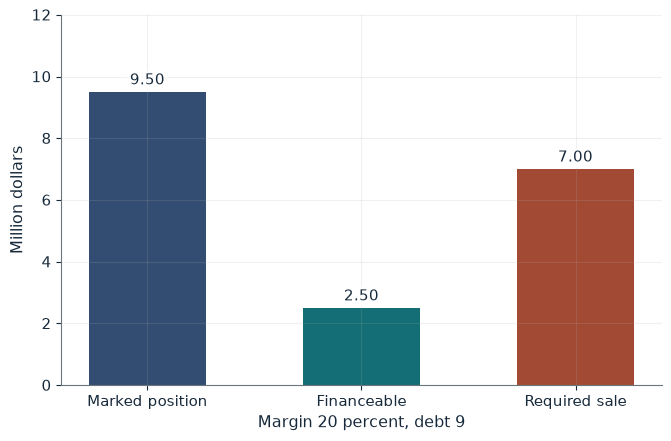

Equity                             0.50
Largest financeable position       2.50
Required sale                      7.00
Sale at a 10 percent margin        4.50
Extra sale from the margin change  2.50

Worked steps:
  1. Equity = 9.5 - 9 = 0.50
  2. Financeable = 0.50 / 0.20 = 2.50
  3. Sale = 9.5 - 2.50 = 7.00
  4. Sale at 10 percent = 9.5 - 0.50 / 0.10 = 4.50
  5. Extra = 7.00 - 4.50 = 2.50

Equity is 9.5 - 9 = 0.50 million. At a 20 percent margin it finances 0.50 / 0.20 = 2.50 million, so the dealer sells 9.5 - 2.50 = 7.00 million. At 10 percent the sale would be 9.5 - 0.50 / 0.10 = 4.50, so the margin change adds 2.50 million of selling.


In [4]:
show(spiral_picture(margin=0.20, mark=9.5))

Change one input, `margin`, and hold the others at the book's values:

In [5]:
sweep(spiral_picture, 'margin', [0.1, 0.15, 0.2, 0.25], {'mark': 9.5}, ['Equity', 'Largest financeable position', 'Required sale', 'Extra sale from the margin change'])

margin | Equity | Largest financeable position | Required sale | Extra sale from the margin change
0.1 | 0.50 | 5.00 | 4.50 | 0.00
0.15 | 0.50 | 3.33 | 6.17 | 1.67
0.2 | 0.50 | 2.50 | 7.00 | 2.50
0.25 | 0.50 | 2.00 | 7.50 | 3.00


Raising the margin from 10 to 20 percent adds 2.5 million dollars of forced selling (7 against 4.5).

## 3. Financial intermediation: delegated monitoring and maturity mismatch

$$100(20)(50)=100{,}000,\qquad 20(400)+2{,}000=10{,}000$$

$$60{,}000-20{,}000=40{,}000,\qquad \frac{40{,}000}{0.75}=53{,}333.33$$

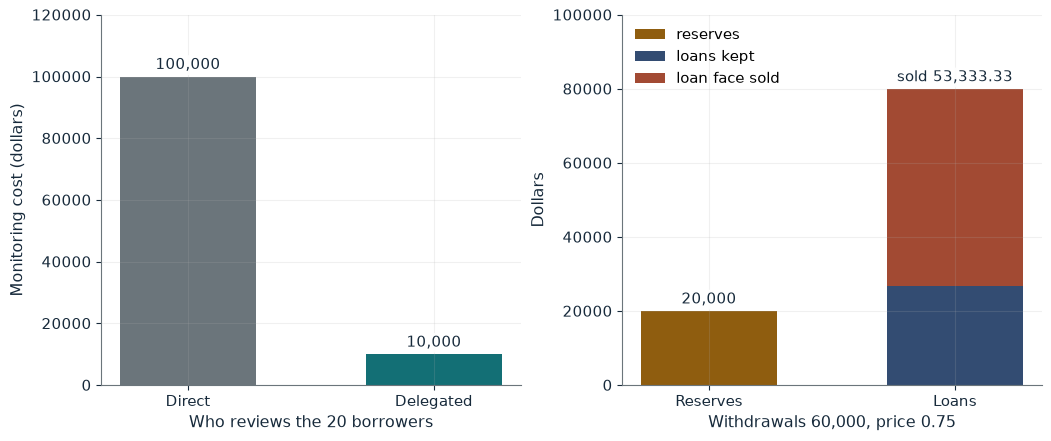

Direct monitoring cost  $100,000
Delegated cost          $10,000
Saving                  $90,000
Cash gap                $40,000.00
Loan face sold          $53,333.33
Loss from the sale      $13,333.33

Worked steps:
  1. Direct = 100 x 20 x 50 = 100,000
  2. Delegated = 20 x 400 + 2,000 = 10,000
  3. Gap = 60,000 - 20,000 = 40,000
  4. Face sold = 40,000 / 0.75 = 53,333.33
  5. Loss = 53,333.33 - 40,000 = 13,333.33

Direct review costs 100 x 20 x 50 = 100,000 and delegation 20 x 400 + 2,000 = 10,000, a saving of 90,000. Withdrawals of 60,000 exceed the 20,000 of reserves by 40,000, so the bank sells 40,000 / 0.75 = 53,333.33 of loan face, losing 53,333.33 - 40,000 = 13,333.33.


In [6]:
show(intermediation_picture(withdraw=60000, price=0.75))

Change one input, `withdraw`, and hold the others at the book's values:

In [7]:
sweep(intermediation_picture, 'withdraw', [15000, 40000, 60000], {'price': 0.75}, ['Cash gap', 'Loan face sold', 'Loss from the sale'])

withdraw | Cash gap | Loan face sold | Loss from the sale
15000 | $0.00 | $0.00 | $0.00
40000 | $20,000.00 | $26,666.67 | $6,666.67
60000 | $40,000.00 | $53,333.33 | $13,333.33


Delegation saves \$90,000 of monitoring. Withdrawals of \$60,000 force the sale of \$53,333.33 of loan face for \$40,000, while \$15,000 is paid from reserves.

## 4. Liquidity crisis: liquidation losses become a credit crunch

$$\frac{40}{0.90}=44.44,\qquad 44.44-40=4.44,\qquad 55.56-50=5.56,\qquad 100-50-40=10$$

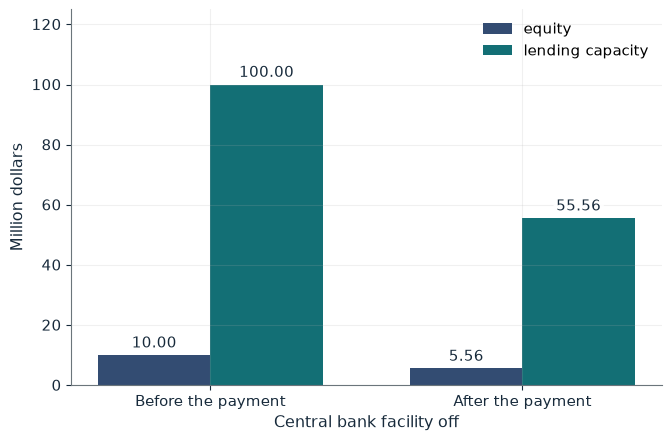

Funding gap       40.00
Loan face sold    44.44
Liquidation loss  4.44
Equity after      5.56
Lending capacity  55.56

Worked steps:
  1. Face sold = 40 / 0.90 = 44.44
  2. Loss = 44.44 - 40 = 4.44
  3. Loans left = 100 - 44.44 = 55.56
  4. Equity = 55.56 - 50 = 5.56
  5. Capacity = 5.5556 / 0.10 = 55.56

Cash covers 20 of the 60 due, leaving a gap of 40. At 0.90 per dollar the bank sells 40 / 0.90 = 44.44 of loans, a loss of 44.44 - 40 = 4.44. Loans left are 100 - 44.44 = 55.56, so equity of 55.56 - 50 = 5.56 supports 5.5556 / 0.10 = 55.56 million of lending. The book rounds equity to 5.56 first and prints 55.6.


In [8]:
show(crunch_picture(price=0.90, facility='off'))

Change one input, `price`, and hold the others at the book's values:

In [9]:
sweep(crunch_picture, 'price', [0.8, 0.9, 1.0], {'facility': 'off'}, ['Loan face sold', 'Liquidation loss', 'Equity after', 'Lending capacity'])

price | Loan face sold | Liquidation loss | Equity after | Lending capacity
0.8 | 50.00 | 10.00 | 0.00 | 0.00
0.9 | 44.44 | 4.44 | 5.56 | 55.56
1.0 | 40.00 | 0.00 | 10.00 | 100.00


At 0.90 equity falls to 5.56 million and lending capacity to 55.56 million (the book prints 55.6 from the rounded 5.56). At 0.80 equity is wiped out. With the facility, equity stays at 10.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

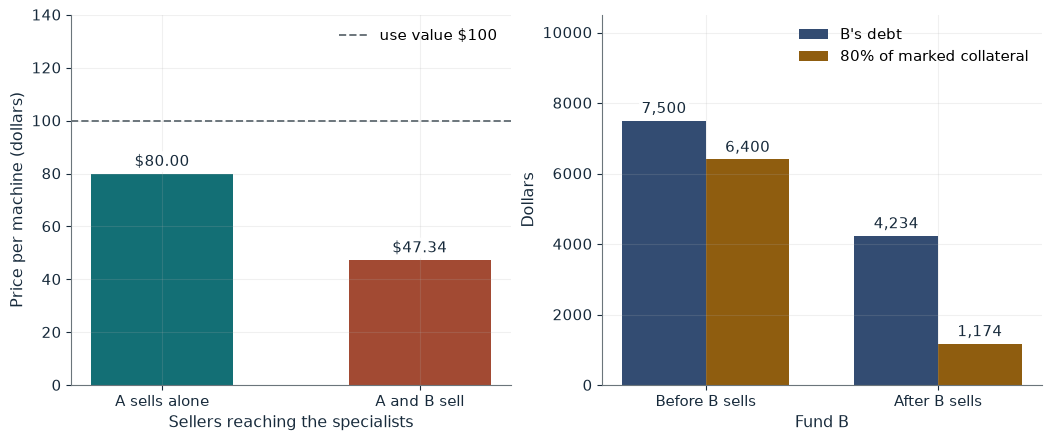

First mark                        $80.00
Covenant capacity at first mark   $6,400.00
Breach                            $1,100.00
Machines B plans to sell          68.75, so 69
Clearing price with both sellers  $47.34
Remaining shortfall               $3,059.76

Worked steps:
  1. First mark = 8,000 / 100 = 80.00
  2. Capacity = 0.80 x 80.00 x 100 = 6,400.00
  3. Breach = 7,500 - 6,400.00 = 1,100.00
  4. x = 1,100.00 / (80.00 x 0.20) = 68.75, round up to 69
  5. Clearing price = 8,000 / 169 = 47.3373
  6. Debt = 7,500 - 69 x 47.3373 = 7,500 - 3,266.27 = 4,233.73
  7. Capacity = 0.80 x 31 x 47.3373 = 1,173.96
  8. Shortfall = 4,233.73 - 1,173.96 = 3,059.76

With $8,000 of specialist cash, A alone clears at 8,000 / 100 = 80.00. B's capacity is 0.80 x 80.00 x 100 = 6,400.00, a breach of 7,500 - 6,400.00 = 1,100.00. Solving 7,500 - 80.00x = 0.80 x 80.00 x (100 - x) gives x = 68.75, so B plans 69 sales. With 169 machines for sale the price falls to 8,000 / 169 = 47.3373. Debt becomes 4,233.7

In [10]:
show(fire_sale_picture(cash=8000))

## Practice

**1.** With 9,000 dollars of specialist cash, how many machines must B plan to sell and what shortfall remains?

<details><summary>Answer</summary>

p = 90, breach 300, x = 300 / 18 = 16.67 so 17; price 9,000 / 117 = 76.92; debt 6,192.31 against capacity 5,107.69; shortfall 1,084.62.

</details>

**2.** With the mark at 9.8 and a 15 percent margin, what must the dealer sell?

<details><summary>Answer</summary>

Equity 0.8; financeable 0.8 / 0.15 = 5.33; sale 9.8 - 5.33 = 4.47 million dollars.

</details>

**3.** With price 0.80 and no facility, what are equity and lending capacity?

<details><summary>Answer</summary>

Face sold 40 / 0.80 = 50; loans left 50; equity 50 - 50 = 0; capacity 0.

</details>